# EstateWise: Real Estate Valuation

## Project Overview

This project estimates historical property prices per unit area
using the UCI Real Estate Valuation dataset.

The workflow includes data inspection, exploratory data analysis,
model comparison, cross-validation, hyperparameter tuning,
held-out test evaluation, and deployment through a Streamlit application.

## Prediction Task

- Task type: Regression
- Target: House price per unit area
- Target unit: 10,000 New Taiwan Dollars (TWD) per ping
- Geographic scope: Sindian District, New Taipei City, Taiwan
- Intended use: Educational demonstration

## Scope and Limitations

The model is not validated for current property prices,
Indian real estate markets, or professional valuation decisions.

## Dataset Reference

Yeh, I. (2018). Real Estate Valuation [Dataset].
UCI Machine Learning Repository.
DOI: 10.24432/C5J30W.

In [3]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split

# Locate the project from either the root or notebooks directory.
current_dir = Path.cwd()

if (current_dir / "data" / "real_estate.xlsx").exists():
    PROJECT_DIR = current_dir
elif (current_dir.parent / "data" / "real_estate.xlsx").exists():
    PROJECT_DIR = current_dir.parent
else:
    raise FileNotFoundError(
        "Dataset not found. Open this notebook from the EstateWise project."
    )

DATA_PATH = PROJECT_DIR / "data" / "real_estate.xlsx"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

print("Python executable:", sys.executable)
print("Project directory:", PROJECT_DIR)
print("Dataset found:", DATA_PATH.exists())

Python executable: c:\EstateWise\.venv\Scripts\python.exe
Project directory: c:\EstateWise
Dataset found: True


## 1. Dataset Loading and Initial Inspection

This section checks the dataset dimensions, column names,
data types, missing values, and exact duplicate records.

The record identifier is inspected separately and will not
be used as a predictive feature.

In [4]:
df_raw = pd.read_excel(DATA_PATH)

print("Dataset shape:", df_raw.shape)

print("\nFirst five records:")
display(df_raw.head())

print("\nColumn information:")
df_raw.info()

print("\nMissing values per column:")
display(df_raw.isna().sum().to_frame("Missing Values"))

# Check duplicates without the unique record identifier.
duplicate_count = (
    df_raw.drop(columns=["No"]).duplicated().sum()
)

print(
    "\nExact duplicate records excluding the identifier:",
    duplicate_count
)

Dataset shape: (414, 8)

First five records:


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1



Column information:
<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB

Missing values per column:


,Missing Values
No,0
X1 transaction date,0
X2 house age,0
X3 distance to the nearest MRT station,0
X4 number of convenience stores,0
X5 latitude,0
X6 longitude,0
Y house price of unit area,0



Exact duplicate records excluding the identifier: 0


## 2. Feature Preparation and Train–Test Split

Column names are standardized for readability. The record identifier
is excluded because it is not a property characteristic.

Six input features are used to predict price per unit area.

The original 80/20 split is reproduced using random_state=42.
Exploratory analysis is restricted to the training subset.

This notebook documents the existing project workflow; the saved
model is not modified in this section.

In [5]:
# Standardize column names.
df = df_raw.rename(columns={
    "X1 transaction date": "transaction_date",
    "X2 house age": "house_age",
    "X3 distance to the nearest MRT station": "mrt_distance",
    "X4 number of convenience stores": "stores",
    "X5 latitude": "latitude",
    "X6 longitude": "longitude",
    "Y house price of unit area": "price_per_unit_area"
}).drop(columns=["No"])

feature_columns = [
    "transaction_date",
    "house_age",
    "mrt_distance",
    "stores",
    "latitude",
    "longitude"
]

X = df[feature_columns]
y = df["price_per_unit_area"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

train_df = X_train.copy()
train_df["price_per_unit_area"] = y_train

print("Input features:", X.shape[1])
print("Training properties:", len(X_train))
print("Test properties:", len(X_test))

print("\nMissing values in the prepared dataset:")
print(df.isna().sum().to_string())

print(
    "\nExact duplicate records excluding the identifier:",
    df.duplicated().sum()
)

print("\nTraining-data preview:")
display(train_df.head())

Input features: 6
Training properties: 331
Test properties: 83

Missing values in the prepared dataset:
transaction_date       0
house_age              0
mrt_distance           0
stores                 0
latitude               0
longitude              0
price_per_unit_area    0

Exact duplicate records excluding the identifier: 0

Training-data preview:


,transaction_date,house_age,mrt_distance,stores,latitude,longitude,price_per_unit_area
192,2013.166667,43.8,57.58945,7,24.96750,121.54069,42.7
234,2013.250000,8.0,2216.61200,4,24.96007,121.51361,23.9
5,2012.666667,7.1,2175.03000,3,24.96305,121.51254,32.1
45,2013.083333,36.6,488.81930,8,24.97015,121.54494,38.3
245,2013.416667,7.5,639.61980,5,24.97258,121.54814,40.8


## 3. Exploratory Data Analysis

The following analysis describes the training subset only.

It examines the target distribution, feature ranges, and
relationships between property characteristics and price.

These plots are being documented after the initial model development.
They are not presented as evidence that the original modelling
choices were made from these plots.

Training-data summary:


,transaction_date,house_age,mrt_distance,stores,latitude,longitude,price_per_unit_area
count,331.000,331.000,331.000,331.000,331.000,331.000,331.000
mean,2013.167,17.289,1059.604,4.145,24.969,121.534,38.392
std,0.282,11.327,1217.930,2.954,0.012,0.015,13.735
min,2012.667,0.000,23.383,0.000,24.932,121.475,7.600
25%,2012.917,8.450,289.325,1.000,24.963,121.530,28.250
50%,2013.167,15.900,492.231,4.000,24.971,121.539,39.300
75%,2013.417,27.200,1442.932,6.000,24.978,121.543,46.600
max,2013.583,43.800,6306.153,10.000,25.015,121.566,117.500


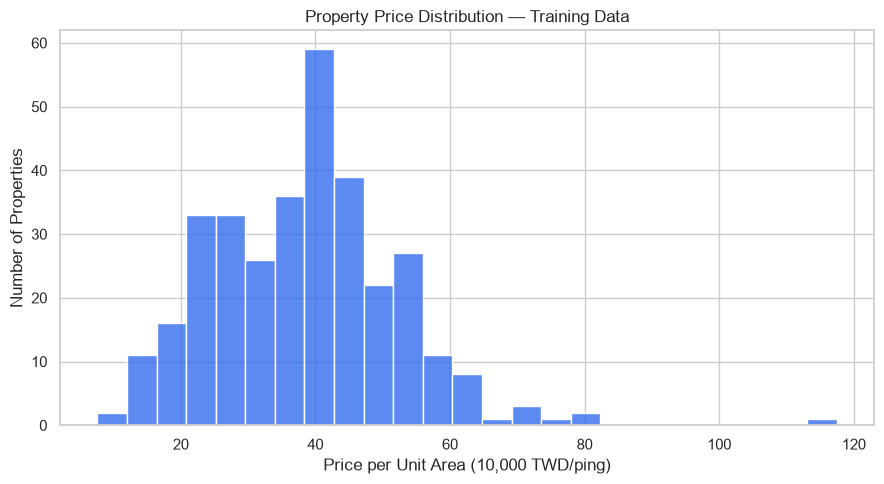

Chart saved: results/figures/01_price_distribution.png


In [6]:
print("Training-data summary:")
display(train_df.describe().round(3))

train_df.describe().to_csv(
    RESULTS_DIR / "training_data_summary.csv"
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=train_df,
    x="price_per_unit_area",
    bins=25,
    color="#2563eb",
    ax=ax
)

ax.set_title("Property Price Distribution — Training Data")
ax.set_xlabel("Price per Unit Area (10,000 TWD/ping)")
ax.set_ylabel("Number of Properties")

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "01_price_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Chart saved: results/figures/01_price_distribution.png")

### 3.1 Property Characteristics and Price

The following scatter plots examine the relationship between
price per unit area and:

- Property age
- Distance to the nearest MRT station

Each point represents one property in the training subset.
These relationships are descriptive and do not establish causation.

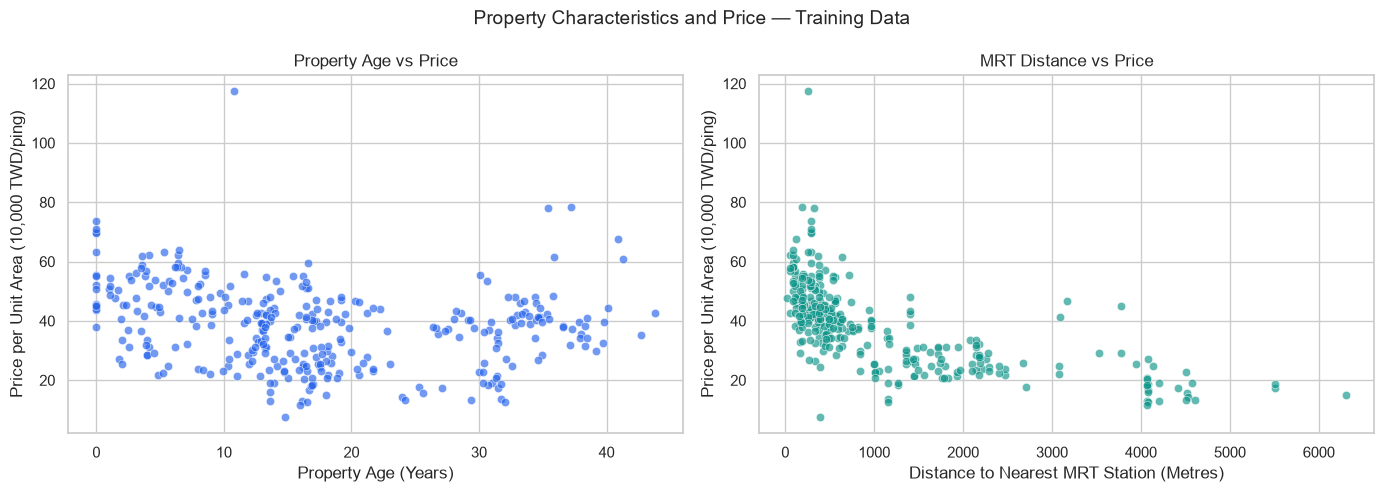

Saved: results/figures/02_property_relationships.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Property age versus price
sns.scatterplot(
    data=train_df,
    x="house_age",
    y="price_per_unit_area",
    color="#2563eb",
    alpha=0.65,
    ax=axes[0]
)

axes[0].set_title("Property Age vs Price")
axes[0].set_xlabel("Property Age (Years)")
axes[0].set_ylabel("Price per Unit Area (10,000 TWD/ping)")

# MRT distance versus price
sns.scatterplot(
    data=train_df,
    x="mrt_distance",
    y="price_per_unit_area",
    color="#0d9488",
    alpha=0.65,
    ax=axes[1]
)

axes[1].set_title("MRT Distance vs Price")
axes[1].set_xlabel("Distance to Nearest MRT Station (Metres)")
axes[1].set_ylabel("Price per Unit Area (10,000 TWD/ping)")

fig.suptitle(
    "Property Characteristics and Price — Training Data",
    fontsize=14
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "02_property_relationships.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved: results/figures/02_property_relationships.png")

### 3.2 Correlation Analysis

The Pearson correlation matrix summarizes pairwise linear
relationships among numerical variables in the training subset.

Positive values indicate that two variables tend to increase together.
Negative values indicate an inverse linear relationship.

A weak correlation does not rule out a nonlinear relationship.
Correlation does not establish causation or directly measure
a fitted model's feature importance.

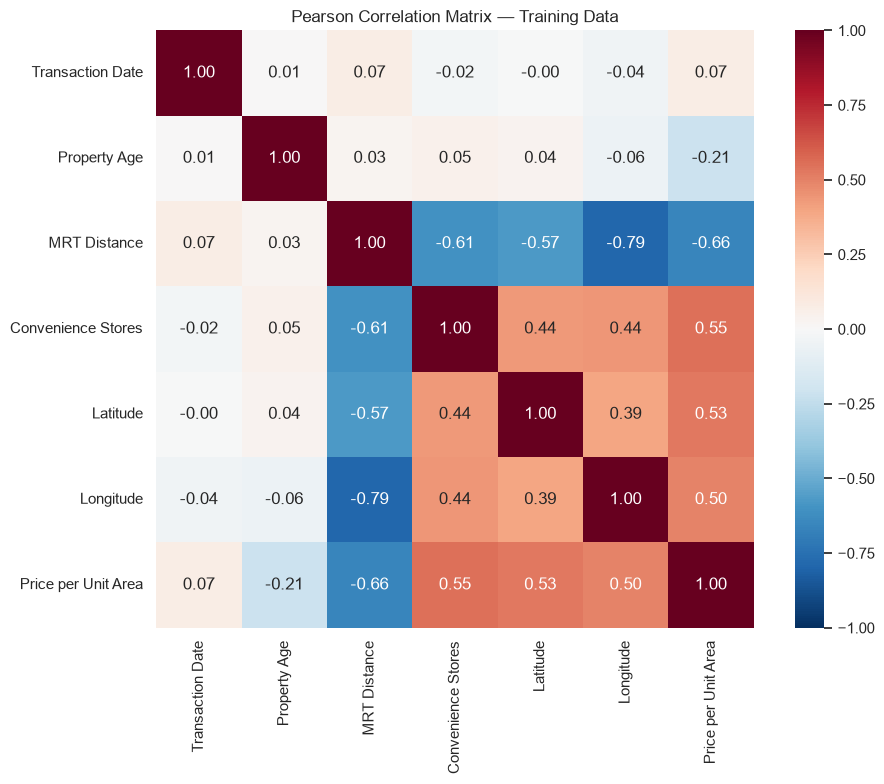

Training-feature correlations with price:
mrt_distance       -0.657
house_age          -0.214
transaction_date    0.075
longitude           0.495
latitude            0.531
stores              0.554


In [8]:
readable_names = {
    "transaction_date": "Transaction Date",
    "house_age": "Property Age",
    "mrt_distance": "MRT Distance",
    "stores": "Convenience Stores",
    "latitude": "Latitude",
    "longitude": "Longitude",
    "price_per_unit_area": "Price per Unit Area"
}

correlation = train_df.rename(
    columns=readable_names
).corr(method="pearson")

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax
)

ax.set_title("Pearson Correlation Matrix — Training Data")

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "03_correlation_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

target_correlations = (
    train_df.corr()["price_per_unit_area"]
    .drop("price_per_unit_area")
    .sort_values()
)

print("Training-feature correlations with price:")
print(target_correlations.round(3).to_string())

target_correlations.to_csv(
    RESULTS_DIR / "feature_target_correlations.csv",
    header=["pearson_correlation"]
)

## 4. Model Comparison

Three regression algorithms were evaluated:

1. Linear Regression with feature scaling
2. Decision Tree Regressor
3. Random Forest Regressor

All models used the same training subset and the same shuffled
5-fold cross-validation splits.

The comparison uses mean absolute error (MAE), root mean squared
error (RMSE), and the coefficient of determination (R²).

The held-out test subset was not used for this comparison.

The following results were generated by train_model.py and are
loaded here for documentation.

Baseline model comparison:


,Model,CV_MAE,CV_RMSE,RMSE_Std,CV_R2
0,Random Forest,5.136,7.821,2.042,0.665
1,Linear Regression,6.545,9.111,2.252,0.548
2,Decision Tree,6.603,10.382,1.795,0.387


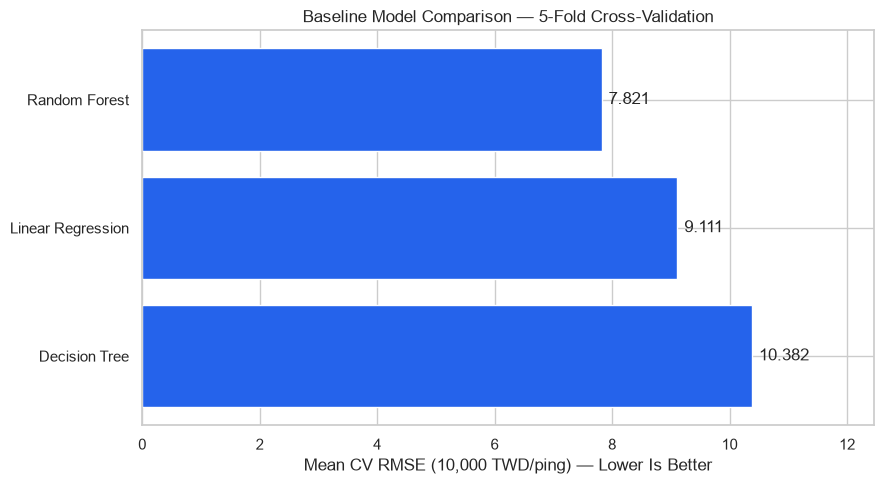

In [9]:
comparison_path = RESULTS_DIR / "model_comparison.csv"

comparison = pd.read_csv(
    comparison_path
).sort_values("CV_RMSE").reset_index(drop=True)

print("Baseline model comparison:")
display(comparison.round(3))

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    comparison["Model"],
    comparison["CV_RMSE"],
    color="#2563eb"
)

ax.invert_yaxis()
ax.bar_label(bars, fmt="%.3f", padding=5)
ax.set_xlim(0, comparison["CV_RMSE"].max() * 1.2)

ax.set_title("Baseline Model Comparison — 5-Fold Cross-Validation")
ax.set_xlabel("Mean CV RMSE (10,000 TWD/ping) — Lower Is Better")
ax.set_ylabel("")

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "04_model_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

### Model Comparison Findings

Random Forest achieved the lowest mean cross-validation RMSE
among the three baseline models:

| Model | Mean CV MAE | Mean CV RMSE | Mean CV R² |
|---|---:|---:|---:|
| Random Forest | 5.136 | 7.821 | 0.665 |
| Linear Regression | 6.545 | 9.111 | 0.548 |
| Decision Tree | 6.603 | 10.382 | 0.387 |

Random Forest also achieved the lowest mean MAE and the highest
mean R² in this comparison. It was therefore selected for
hyperparameter tuning.

These are results from the selected cross-validation setup.
They do not establish that Random Forest is universally superior
or that the differences are statistically significant.

R² is not an accuracy percentage.

## 5. Hyperparameter Tuning

The Random Forest pipeline was tuned using GridSearchCV.

### Search Space

- Number of trees: 100, 200
- Maximum tree depth: None, 5, 10
- Minimum samples per leaf: 1, 2, 4

The search evaluated 18 parameter combinations using 5-fold
cross-validation, resulting in 90 cross-validation fits.

Selection was based on the lowest mean cross-validation RMSE.
The selected pipeline was then fitted on all 331 training records.

The held-out test data was not used for hyperparameter selection.

In [10]:
import json

tuning_results = pd.read_csv(
    RESULTS_DIR / "tuning_results.csv"
)

with open(
    RESULTS_DIR / "final_metrics.json",
    "r",
    encoding="utf-8"
) as file:
    final_metrics = json.load(file)

print("Top five parameter combinations:")

display(
    tuning_results.sort_values("rank_test_score")
    .head(5)
    .round(3)
)

print("\nSelected hyperparameters:")

for parameter, value in final_metrics["best_parameters"].items():
    print(f"{parameter}: {value}")

baseline_rmse = float(
    comparison.loc[
        comparison["Model"] == "Random Forest",
        "CV_RMSE"
    ].iloc[0]
)

selected_rmse = final_metrics["selected_cv_rmse"]

print(f"\nBaseline Random Forest CV RMSE: {baseline_rmse:.3f}")
print(f"Selected Random Forest CV RMSE: {selected_rmse:.3f}")
print(f"CV RMSE reduction: {baseline_rmse - selected_rmse:.3f}")

Top five parameter combinations:


,param_model__n_estimators,param_model__max_depth,param_model__min_samples_leaf,CV_RMSE,std_test_score,rank_test_score
0,200,NaN,4,7.591,2.267,1
1,200,10.0,4,7.591,2.267,2
2,200,5.0,4,7.593,2.290,3
3,100,NaN,4,7.597,2.277,4
4,100,10.0,4,7.599,2.277,5



Selected hyperparameters:
model__max_depth: None
model__min_samples_leaf: 4
model__n_estimators: 200

Baseline Random Forest CV RMSE: 7.821
Selected Random Forest CV RMSE: 7.591
CV RMSE reduction: 0.230


### Tuning Findings

The selected Random Forest configuration used:

- 200 trees
- No fixed maximum tree depth
- A minimum of 4 samples per leaf

Mean cross-validation RMSE decreased from 7.821 to 7.591.

This is an improvement within the cross-validation search used
for model selection. It is not an independent estimate of the
selected model's generalization performance.

The held-out test results are documented in the next section.

## 6. Final Evaluation on Held-Out Test Data

After model selection and hyperparameter tuning, the selected
Random Forest pipeline was evaluated on 83 held-out properties.

The test subset was not used for training, preprocessing fitting,
or hyperparameter selection.

The following metrics and predictions were generated by
train_model.py and are loaded here for documentation.

In [11]:
test_metrics_table = pd.DataFrame({
    "Metric": [
        "Test Properties",
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "R²"
    ],
    "Value": [
        str(final_metrics["test_properties"]),
        f"{final_metrics['test_mae']:.3f}",
        f"{final_metrics['test_rmse']:.3f}",
        f"{final_metrics['test_r2']:.3f}"
    ]
})

display(test_metrics_table)

print("MAE and RMSE unit: 10,000 TWD per ping")
print("R² is not an accuracy percentage.")

test_predictions = pd.read_csv(
    RESULTS_DIR / "test_predictions.csv"
)

print("\nSaved test predictions:", len(test_predictions))
display(
    test_predictions[
        ["actual_price", "predicted_price"]
    ].head(10).round(3)
)

,Metric,Value
0,Test Properties,83
1,Mean Absolute Error (MAE),3.654
2,Root Mean Squared Error (RMSE),5.449
3,R²,0.823


MAE and RMSE unit: 10,000 TWD per ping
R² is not an accuracy percentage.

Saved test predictions: 83


,actual_price,predicted_price
0,45.1,49.229
1,42.3,38.681
2,52.2,53.662
3,37.3,37.405
4,22.8,25.896
5,36.3,42.939
6,53.0,47.968
7,51.4,49.397
8,16.1,18.256
9,59.0,59.336


### 6.1 Prediction Diagnostics

Two plots are used to inspect the held-out predictions:

1. Actual vs Predicted: Points closer to the diagonal reference
   line indicate smaller prediction errors.

2. Residuals vs Predicted: A residual is defined as
   actual price minus predicted price. Positive residuals indicate
   underprediction; negative residuals indicate overprediction.

These plots describe the errors of the selected model and are
not used here to perform further model tuning.

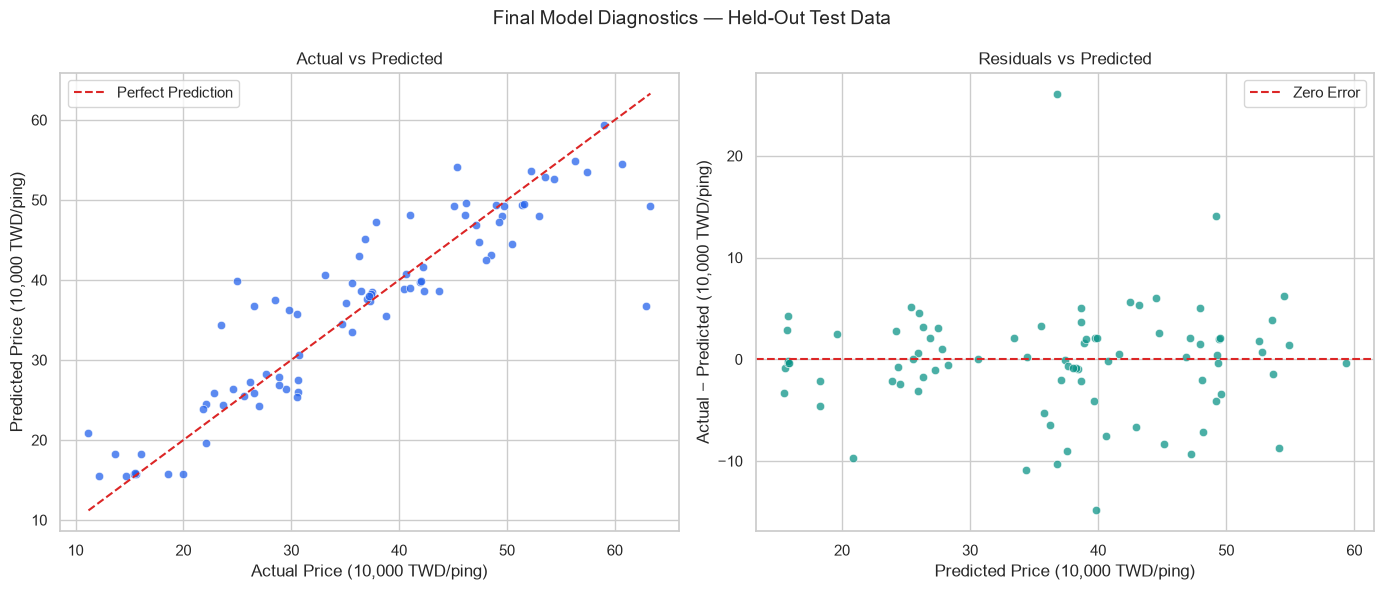

Saved: results/figures/05_final_test_diagnostics.png


In [12]:
actual = test_predictions["actual_price"]
predicted = test_predictions["predicted_price"]
residuals = actual - predicted

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Actual versus predicted
axes[0].scatter(
    actual,
    predicted,
    color="#2563eb",
    alpha=0.75,
    edgecolors="white",
    linewidths=0.5
)

lower = min(actual.min(), predicted.min())
upper = max(actual.max(), predicted.max())

axes[0].plot(
    [lower, upper],
    [lower, upper],
    color="#dc2626",
    linestyle="--",
    label="Perfect Prediction"
)

axes[0].set_title("Actual vs Predicted")
axes[0].set_xlabel("Actual Price (10,000 TWD/ping)")
axes[0].set_ylabel("Predicted Price (10,000 TWD/ping)")
axes[0].legend()

# Residuals versus predicted
axes[1].scatter(
    predicted,
    residuals,
    color="#0d9488",
    alpha=0.75,
    edgecolors="white",
    linewidths=0.5
)

axes[1].axhline(
    y=0,
    color="#dc2626",
    linestyle="--",
    label="Zero Error"
)

axes[1].set_title("Residuals vs Predicted")
axes[1].set_xlabel("Predicted Price (10,000 TWD/ping)")
axes[1].set_ylabel("Actual − Predicted (10,000 TWD/ping)")
axes[1].legend()

fig.suptitle(
    "Final Model Diagnostics — Held-Out Test Data",
    fontsize=14
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "05_final_test_diagnostics.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved: results/figures/05_final_test_diagnostics.png")

### Final Evaluation Findings

The selected model achieved the following results on
83 held-out properties:

- MAE: 3.654
- RMSE: 5.449
- R²: 0.823

MAE and RMSE are expressed in 10,000 TWD per ping.
These values do not represent errors in total property price.

The held-out RMSE was lower than the selected mean
cross-validation RMSE of 7.591. These estimates come from
different evaluation subsets and should not be interpreted
as evidence that the model improved after tuning on test data.

Performance on one held-out split does not establish reliability
across different locations, future transactions, or market conditions.

## 7. Model Persistence and Application

The fitted pipeline and supporting metadata were saved in model.pkl.

The saved artifact includes:

- The fitted Random Forest pipeline
- Expected feature names and order
- Training-data input ranges
- An example input
- Evaluation metrics
- The scikit-learn version used during training

The Streamlit application loads this artifact and generates
predictions without repeating training or hyperparameter tuning.

## 8. Limitations

- The dataset is small, historical, and geographically specific.
- Predictions are not validated for current Indian property markets.
- The target is price per unit area, not total sale price.
- Features absent from the dataset are not considered by the model.
- Valid individual input ranges do not guarantee realistic combinations.
- The application is an educational prototype, not professional advice.

## 9. Conclusion

This project demonstrates an end-to-end regression workflow:
data inspection, training-data exploration, comparison of three
algorithms, cross-validation, hyperparameter tuning, held-out
evaluation, model persistence, and a working local Streamlit application.

GitHub publication, live deployment, and final reporting are
documented separately as they are completed.